In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

from tqdm.notebook import tqdm

plt.style.use('ggplot')
%matplotlib inline

**Задача**

1. Каким распределнием можно моделировать конверсию?

- Бинамиальное распределение (распределение Бернулли)
 $$P_n(k) = C_n^k \cdot p^k \cdot (1-p)^{n-k}$$

2. Каким распредлением можно моделировать выручку (Revenue)?

- Экспоненциальное

3. Каким распредлением можно моделировать ARPPU (Average Revenue Per Paying User. Общий доход платящих пользователей / Количество платящих пользователей)?

- Для достаточно большой выборки по ЦПТ распределение стремится к нормальному, но индивидуальная выручка пользователей часто имеет правостороннюю асимметрию и может моделироваться логнормальным.

4. Каким распределением можно моделировать LTV?

- Логнормальное распределение (правосторонняя ассиметрия)

5. Каким распределением можно моделировать Retention?

- Биномиальное / Бернулли

---

Какие статистические тесты удачней всего для них проверять для проверки гипотез?

1. Z-тест для пропорций, Хи-квадрат Пирсона
2. Бутстрап, t-тест Стьюдента  (при достаточно большой выборке)
3. Бутстрап, t-тест Стьюдента, Манна-Уитни



**Задача**

Вы решили построить распределение зарплат в одной крупной компании и подобрать распределение, которое его лучше всего описывает. Для начала вы решили глазами посмотреть на гистограмму и увидели, что форма распределения, похожего на экспоненциальное, очень сильно зависит от биннинга. Что вы предпримете, чтобы с этим побороться?

---

1. По правилу Фридмана-Диакониса для достаточно большого кол-ва данных выбираем ширину интервалов для построения гистограммы:
$$h = 2 \cdot \frac{(Q_3 - Q_1)}{\sqrt[3]{n}}$$
2. Рассмотрим новую гистограмму с разбиением $h$ и дополним графиком KDE (Kernel Density Estimation/Ядерная оценка плотности). KDE сглаживает ступенчатость гистограммы и показывает гладкую и непрерывную кривую распределения
3. Построить график эмпирической функции распределения для визуализации закона распределения
4.  QQ-Plot для сравнения эмпирического распределения данных с теоретическим распределением


Минимальная ЗП: 63,742 руб.
Медианная ЗП: 211,103 руб.
Максимальная ЗП: 1,715,157 руб.



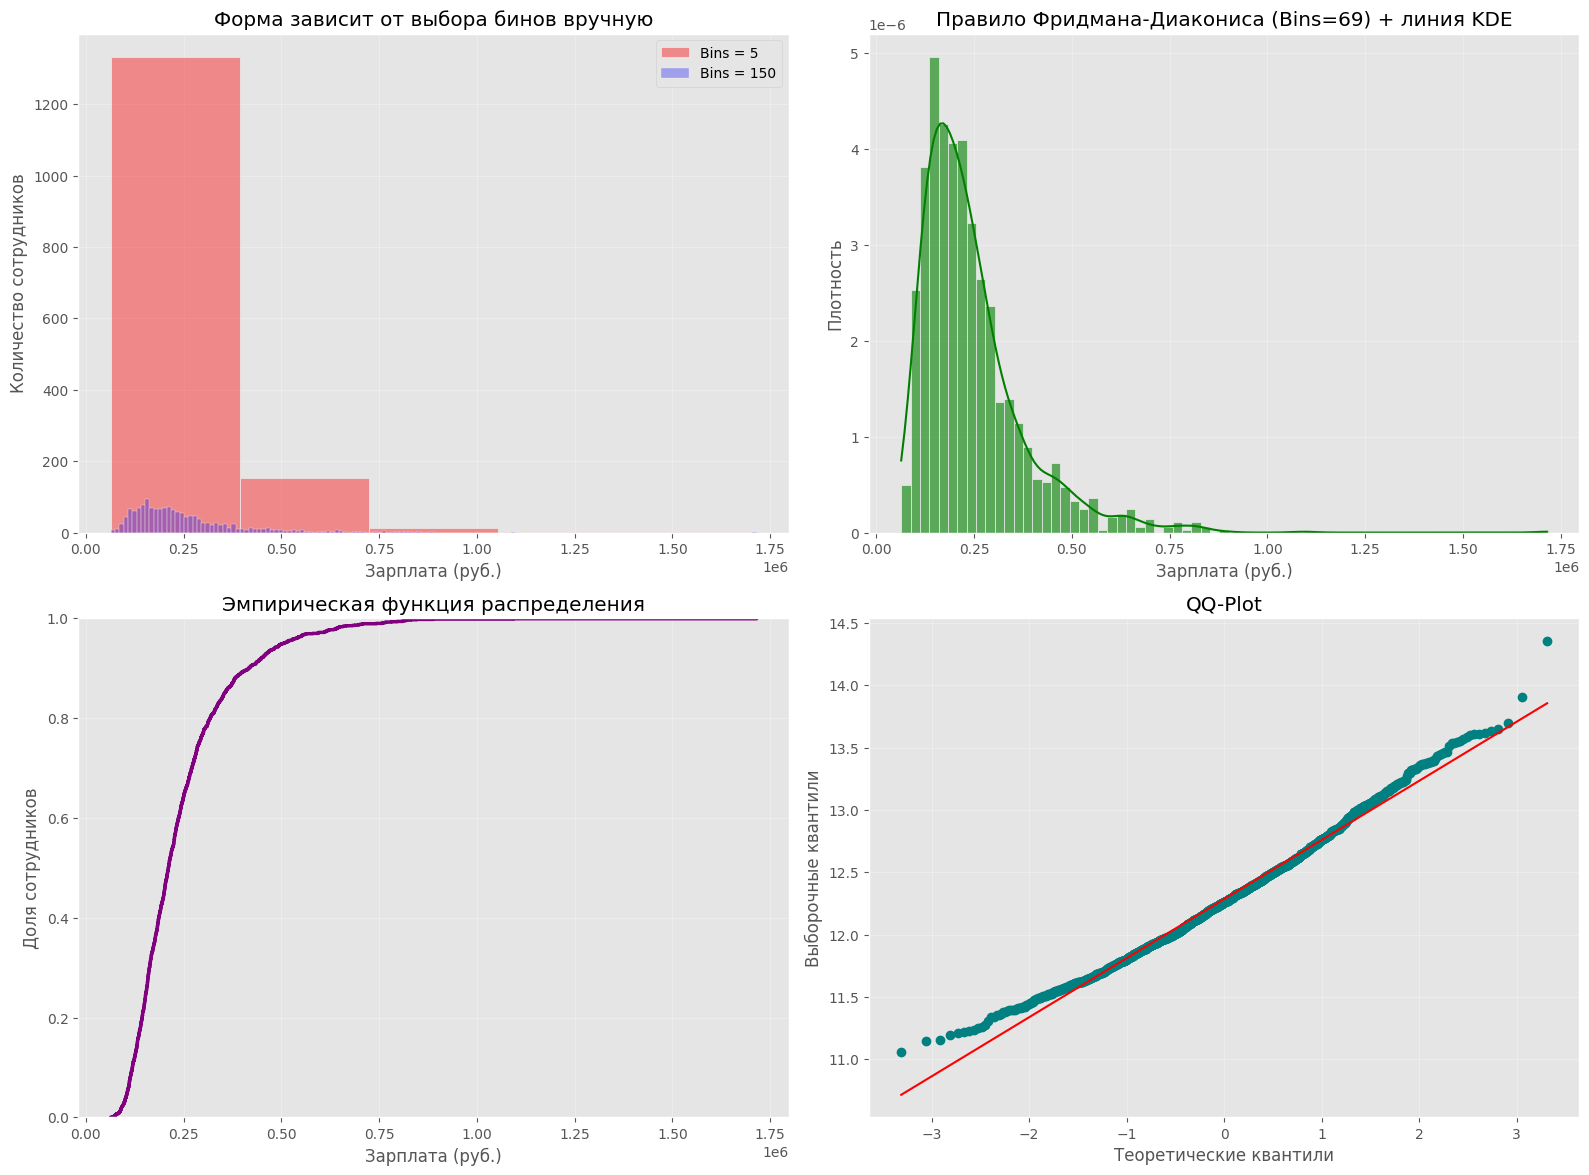

In [ ]:
# логнормальное распределение: большинство получает среднюю ЗП, единицы — очень много
np.random.seed(42)
n_employees = 1500
salaries = np.random.lognormal(mean=1.2, sigma=0.6, size=n_employees) * 50000 + 40000

print(f"Минимальная ЗП: {salaries.min():,.0f} руб.")
print(f"Медианная ЗП: {np.median(salaries):,.0f} руб.")
print(f"Максимальная ЗП: {salaries.max():,.0f} руб.\n")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Слишком мало или слишком много бинов
sns.histplot(salaries, bins=5, color='red', alpha=0.4, label='Bins = 5', ax=axes[0, 0])
sns.histplot(salaries, bins=150, color='blue', alpha=0.3, label='Bins = 150', ax=axes[0, 0])
axes[0, 0].set_title('Форма зависит от выбора бинов вручную')
axes[0, 0].set_xlabel('Зарплата (руб.)')
axes[0, 0].set_ylabel('Количество сотрудников')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

#Фридмана-Диакониса + KDE
q25, q75 = np.percentile(salaries, [25, 75])
iqr = q75 - q25
bin_width = 2 * iqr / (len(salaries) ** (1/3))
fd_bins = int((salaries.max() - salaries.min()) / bin_width)

sns.histplot(salaries, bins=fd_bins, kde=True, color='green', stat='density', alpha=0.6, ax=axes[0, 1])
axes[0, 1].set_title(f'Правило Фридмана-Диакониса (Bins={fd_bins}) + линия KDE')
axes[0, 1].set_xlabel('Зарплата (руб.)')
axes[0, 1].set_ylabel('Плотность')
axes[0, 1].grid(True, alpha=0.3)

#ECDF (Функция накопленной вероятности)
sns.ecdfplot(salaries, color='purple', linewidth=2.5, ax=axes[1, 0])
axes[1, 0].set_title('Эмпирическая функция распределения')
axes[1, 0].set_xlabel('Зарплата (руб.)')
axes[1, 0].set_ylabel('Доля сотрудников')
axes[1, 0].grid(True, alpha=0.3)

#  QQ-Plot (Проверка на логнормальное распределение)
stats.probplot(np.log(salaries), dist=stats.norm, plot=axes[1, 1])
axes[1, 1].get_lines()[0].set_markerfacecolor('teal')
axes[1, 1].get_lines()[0].set_markeredgecolor('teal')
axes[1, 1].get_lines()[1].set_color('red')
axes[1, 1].set_title('QQ-Plot')
axes[1, 1].set_xlabel('Теоретические квантили')
axes[1, 1].set_ylabel('Выборочные квантили')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Задача**

В МТС банке запустили аб-тест на странице, где можно оформить
заявку на банковскую карту. В варианте А из 2574 клиентов,
зашедших на страницу, на баннер нажали 350, в варианте Б из
2855 нажали 375. Какой вариант баннера предложить продакту и
почему?

In [ ]:
alpha = 0.05

In [ ]:
n_1 = 2574
m_1 = 350

n_2 = 2855
m_2 = 375

Выборки больше 30 можно использовать z-тест для пропорций

In [ ]:
w_1 = m_1 / n_1

w_2 = m_2 / n_2

w = (m_1 + m_2)/(n_1 + n_2)

print(w_1, w_2)

0.13597513597513597 0.13134851138353765


Предполагаем, что $p_1 > p_2$

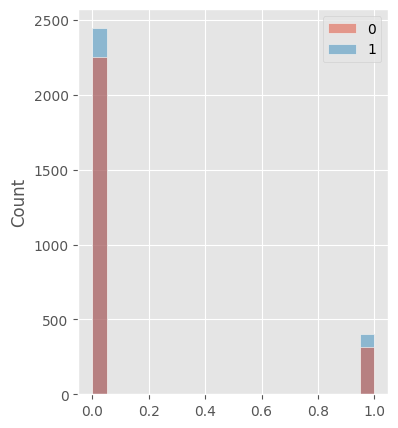

In [ ]:
X = stats.bernoulli.rvs(w_1, size=n_1)
Y = stats.bernoulli.rvs(w_2, size=n_2)

plt.figure(figsize=(4, 5))

sns.histplot([X,Y], bins=20);


In [ ]:
#статистика критерия
U = (w_1 - w_2)/(np.sqrt(w * (1 - w) * (1/n_1 + 1/n_2)))

print(U)

0.5004133076147605


In [ ]:
norm_rv = stats.norm(loc=0, scale=1)

u_kr = norm_rv.ppf(1/2 - alpha)

print(u_kr)

-0.12566134685507402


In [ ]:
if (U < u_kr):
    print('принимаем H_0')
else:
    print('отвергаем H_0')

отвергаем H_0


In [ ]:
md = w_1 - w_2

print(md)

0.004626624591598322


In [ ]:
se = (np.sqrt(w * (1 - w) * (1/n_1 + 1/n_2)))

print(se)

0.00924560662395512


**Задача**

Допустим, вы участвуете в соревновании дизайнеров, на новый макет сайта.
После разработки участники самостоятельно проводят опрос клиентов.

• Вы опросили 100 человек, 60 людям он понравился больше старого

• Ваш коллега опросил 10 людей, 7 человек предпочли его сайт старому

• Начальник сравнивает конверсию (сколько "успеха" в процентах)

• Как объяснить, что ваш вариант лучше?

In [ ]:
alpha = 0.05
gamma = 1 - alpha

In [ ]:
norm_rv = stats.norm(loc=0, scale=1)

u_gamma = norm_rv.ppf(alpha/2)

print(u_gamma)

-1.9599639845400545


In [ ]:
n_1 = 100
m_1 = 60
w_1 = m_1 / n_1

n_2 = 10
m_2 = 7
w_2 = m_2 / n_2

In [ ]:
left_1 = w_1 + u_gamma*np.sqrt((w_1*(1- w_1) )/n_1)
right_1 = w_1 - u_gamma*np.sqrt((w_1*(1- w_1) )/n_1)


print("Доверительный интервал [{:.4}; {:.4}] ширины {:.4}".format(left_1, right_1, right_1 - left_1))

Доверительный интервал [0.504; 0.696] ширины 0.192


In [ ]:
left_2 = w_2 + u_gamma*np.sqrt((w_2*(1- w_2) )/n_2)
right_2 = w_2 - u_gamma*np.sqrt((w_2*(1- w_2) )/n_2)

print("Доверительный интервал [{:.4}; {:.4}] ширины {:.4}".format(left_2, right_2, right_2 - left_2))


Доверительный интервал [0.416; 0.984] ширины 0.5681


**Задача**

Какие еще методы построения доверительных интервалов, кроме основанного на z критерии пропроций здесь можно попробовать применить?

Примените и сравните с доверительным интервалом на основе z критерия пропорций.

**Задача**

In [ ]:
#from math import asin

#import numpy as np

from scipy import stats
from statsmodels.stats.power import TTestIndPower, tt_ind_solve_power, zt_ind_solve_power
from statsmodels.stats.proportion import proportion_effectsize
from statsmodels.stats.meta_analysis import effectsize_smd

from typing import Union

import matplotlib.pyplot as plt
import seaborn as sns
#import plotly.graph_objects as go

In [ ]:
#Расчёт effect_size для пропорций (качественная)
def calc_propotion_effect_size(conv1: int, nobs1: int, conv2: int, nobs2: int):
    p1, p2 = conv1 / nobs1, conv2 / nobs2

    # формула
    #return 2  * asin(np.sqrt(p1)) - 2 * asin(np.sqrt(p2))

    # библиотека
    return proportion_effectsize(p1, p2)

#Расчёт effect_size для непрерывных метрик (количественная)
def calc_continuous_effect_size(mean1: Union[float, int],
                                std1: Union[float, int],
                                mean2: Union[float, int],
                                std2: Union[float, int],
                                nobs1: int = 10_000,
                                nobs2: int = 10_000):

    # формула
    #return (mean1 - mean2) / np.sqrt((std1**2 + std2**2) / 2)

    # библиотека
    return effectsize_smd(mean1, std1, nobs1, mean2, std2, nobs2)[0]

In [ ]:
#Расчёт минимально необходимой выборки для пропорций
def calc_sample_size_proportion(effect_size: float,
                                alpha: float = .05,
                                beta: float = .2,
                                ratio: Union[float, int] = 1):

    n = zt_ind_solve_power(effect_size=effect_size,
                           alpha=alpha,
                           power=(1 - beta),
                           ratio=ratio,
                  )
    return int(n)

#Расчёт минимально необходимой выборки для непрерывной метрики
def calc_sample_size_continuous(effect_size: float,
                                alpha: float = .05,
                                beta: float = .2,
                                ratio: Union[float, int] = 1):

    n = tt_ind_solve_power(effect_size=effect_size,
                           alpha=alpha,
                           power=(1 - beta),
                           ratio=ratio,
                  )
    return int(n)

**Задача**

Мы хотим провести АБ-тест баннеров. Нынешняя конверсия в клик на баннер (CTR) равна 1.5%. Мы предполагаем, что с новыми баннерами CTR вырастет до 1.7%. Определите, сколько юзеров нам нужно отправить на каждую версию с уровнем доверия 95%.

In [ ]:
p1, p2, gamma = 1.5/100, 1.7/100, 0.95
alpha = 1-gamma
beta = 0.2

In [ ]:
effect_size = proportion_effectsize(p1, p2)

analysis = TTestIndPower()
size = analysis.solve_power(effect_size=effect_size, nobs1= None, alpha= alpha, power=1-beta, ratio=1, alternative='two-sided')
int(size) # объем одной выборки

61727

In [ ]:
zt_ind_solve_power(effect_size=effect_size, alpha=alpha, power=1 - beta)

61726.47090823281

**Задача**

Дизайнер предложил добавить рекомендательную систему на этапе формирования корзины. Нынешний средний чек равен 2167 рублей, а стандартная ошибка (SD) равна 69. Мы предполагаем, что в новой версии средний чек вырастет 2180. Определите, сколько юзеров нам нужно отправить на каждую версию с уровнем доверия 95%.

https://www.statulator.com/SampleSize/ss2M.html

In [ ]:
Mx, My = 2167, 2180
SDx, SDy = 69, 69
alpha = 0.05

effect_size = calc_continuous_effect_size(Mx, SDx, My, SDy)
effect_size

-0.18839873108913158

In [ ]:
tt_ind_solve_power(effect_size=effect_size, alpha=alpha, power=0.8, ratio=1)

443.22546990430044

**Задача**

Продакт на главной mail.ru решил протестировать в рекомендательной ленте контента вместо карточек со статьями видеоплеер с короткими видео. Нынешний таймспент на юзера в день в среднем равен 25 минут, а стандартная ошибка (SD) равна 156. Мы предполагаем, что в новой версии таймспент на юзера в день изменится на 10%. Средний трафик 20000 человек в день. Посчитайте сколько дней необходимо держать эксперимент при альфа 0.05 и бета 0.2

In [ ]:
Mx, SDx, My, n = 25, 156, 25*1.1, 20000
alpha = 0.05
beta = 0.2

In [ ]:
effect_size = effectsize_smd(Mx, SDx, n, My, SDx, n)[0]
effect_size

-0.016025340527968824

In [ ]:
int(tt_ind_solve_power(effect_size=effect_size, alpha=alpha, power=(1 - beta))) * 2 / n

6.1126

Держать эксперимент необходимо 7 дней.

**Задаа**

Наша продуктовая команда в ecommerce магазине планирует запустить тест, направленный на ускорение загрузки сайта. Одна из основных метрик bounce rate в GA = 40%. Мы предполагаем, что при оптимизации сайта она изменится минимум на 20%. Средний трафик 4000 человек в день. Посчитайте сколько нам нужно дней держать эксперимент при альфа 0.05 и бета 0.2.

In [ ]:
p1, p2 = 0.4, 0.4*(1-0.2)
alpha = 0.05
beta = 0.2
n = 4000

In [ ]:
effect_size = proportion_effectsize(p1, p2)
effect_size

0.16690997264630902

**Задача**

Наша продуктовая команда в ecommerce магазине планирует запустить тест, направленный на ускорение загрузки сайта. Одна из основных метрик bounce rate в GA = 40%. Мы предполагаем, что при оптимизации сайта она изменится минимум на 20%. Средний трафик 4000 человек в день. Посчитайте сколько нам нужно дней держать эксперимент при альфа = 0.05 и бета 0.2.

In [ ]:
p1, p2 = 0.4, 0.4*(1-0.2)
alpha = 0.05
beta = 0.2
n = 4000

In [ ]:
effect_size = proportion_effectsize(p1, p2)
effect_size

0.16690997264630902

In [ ]:
int(zt_ind_solve_power(effect_size=effect_size, alpha=alpha, power=(1 - beta))) * 2 / n

0.2815

При трафике в 4000 человек в день достаточно одного дня эксперимента.

**Задача**

На сайте запущен А/В тест с целью увеличить доход.
В приложенном excel файле вы найдете сырые данные по результатам эксперимента:

user_id
variant_name - тип выборки
revenue - доход принесенный пользователем
Проанализируйте результаты эксперимента и напишите свои рекомендации менеджеру


In [ ]:
df = pd.read_excel("AB_Test_Results (3).xlsx")

df


C:\Users\Admin\anaconda3\lib\site-packages\openpyxl\worksheet\_reader.py:312: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,USER_ID,VARIANT_NAME,REVENUE
0,737,variant,0.0
1,2423,control,0.0
2,9411,control,0.0
3,7311,control,0.0
4,6174,variant,0.0
...,...,...,...
9995,1981,control,0.0
9996,502,variant,0.0
9997,9214,variant,0.0
9998,7741,control,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   USER_ID       10000 non-null  int64  
 1   VARIANT_NAME  10000 non-null  object 
 2   REVENUE       10000 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 234.5+ KB


In [ ]:
df.isna().sum()

USER_ID         0
VARIANT_NAME    0
REVENUE         0
dtype: int64

Проверим распределение посльзователей по группам

In [ ]:
double = df.groupby('USER_ID', as_index=False).agg({'VARIANT_NAME': pd.Series.nunique}).query('VARIANT_NAME > 1')
double


,USER_ID,VARIANT_NAME
1,3,2
6,10,2
11,18,2
15,25,2
23,40,2
...,...,...
6310,9978,2
6311,9979,2
6313,9982,2
6321,9996,2


Посчитаем, сколько типов выборки встречается у каждого пользователя и избавимся от некорретных строк

In [ ]:

df = df[~df['USER_ID'].isin(double['USER_ID'])].sort_values('USER_ID').reset_index(drop=True)
df


,USER_ID,VARIANT_NAME,REVENUE
0,2,control,0.0
1,2,control,0.0
2,2,control,0.0
3,4,variant,0.0
4,5,variant,0.0
...,...,...,...
6065,9992,control,0.0
6066,9993,control,0.0
6067,9995,variant,0.0
6068,9995,variant,0.0


Проверим на полные дубли

In [ ]:
df.duplicated().sum()

1249

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df


,USER_ID,VARIANT_NAME,REVENUE
0,2,control,0.0
1,4,variant,0.0
2,5,variant,0.0
3,6,variant,0.0
4,9,variant,0.0
...,...,...,...
4816,9990,variant,0.0
4817,9992,control,0.0
4818,9993,control,0.0
4819,9995,variant,0.0


Из 10000 записей осталось 4821 (48%).

**Первая рекомендация: проверить систему сплитования трафика.**

Еще систему сплитирования можно на А/А тесте по метрикам

In [ ]:
df['REVENUE'].describe()

count    4821.000000
mean        0.134802
std         2.999336
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       196.010000
Name: REVENUE, dtype: float64

In [ ]:
#Дропнем выброс

max = df.REVENUE.max()

df = df[df['REVENUE'] < max]

df



,USER_ID,VARIANT_NAME,REVENUE,conversion
0,737,variant,0.0,0
1,2423,control,0.0,0
2,9411,control,0.0,0
3,7311,control,0.0,0
4,6174,variant,0.0,0
...,...,...,...,...
9995,1981,control,0.0,0
9996,502,variant,0.0,0
9997,9214,variant,0.0,0
9998,7741,control,0.0,0


**Задача**

Попробуйте другие методы обнаружения выбросов. Например метод межквартильного размаха или даже методы ML, основанные на ближайших соседях.

In [ ]:
df['VARIANT_NAME'].value_counts()


variant    5015
control    4983
Name: VARIANT_NAME, dtype: int64

In [ ]:
CONTROL = df[df['VARIANT_NAME']=='control']
VARIANT = df[df['VARIANT_NAME']=='variant']

In [ ]:
CONTROL.describe()

,USER_ID,REVENUE,conversion
count,4983.000000,4983.000000,4983.000000
mean,4989.767409,0.089703,0.015854
std,2905.342888,1.159256,0.124923
min,2.000000,0.000000,0.000000
25%,2466.000000,0.000000,0.000000
50%,4965.000000,0.000000,0.000000
75%,7576.500000,0.000000,0.000000
max,10000.000000,41.530000,1.000000


In [ ]:
VARIANT.describe()

,USER_ID,REVENUE,conversion
count,5015.000000,5015.000000,5015.000000
mean,4973.194018,0.058393,0.014158
std,2876.455722,1.022240,0.118152
min,3.000000,0.000000,0.000000
25%,2476.000000,0.000000,0.000000
50%,4959.000000,0.000000,0.000000
75%,7415.500000,0.000000,0.000000
max,10000.000000,57.460000,1.000000


Видно, что в VARINAT среднее поменьше, но там и выборка поменьше. Да и вообще среднее неустойчиво к выбросам

In [ ]:
df['conversion'] = df['REVENUE'].apply(lambda x: int(x>0))
df.pivot_table(index='VARIANT_NAME',
               columns='conversion',
               values='USER_ID',
               aggfunc='count',
               margins=True)

C:\Users\Admin\AppData\Local\Temp\ipykernel_6088\1086124965.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['conversion'] = df['REVENUE'].apply(lambda x: int(x>0))


conversion,0,1,All
VARIANT_NAME,,,
control,4904,79,4983
variant,4944,71,5015
All,9848,150,9998


In [ ]:
A = df.query('VARIANT_NAME == "control"')
B = df.query('VARIANT_NAME == "variant"')
n1, n2 = A.shape[0], B.shape[0]
m1, m2 = A[A['conversion']==1].shape[0], B[B['conversion']==1].shape[0]

In [ ]:
p1, p2 = m1/n1, m2/n2
p1, p2

(0.015853903271121815, 0.01415752741774676)

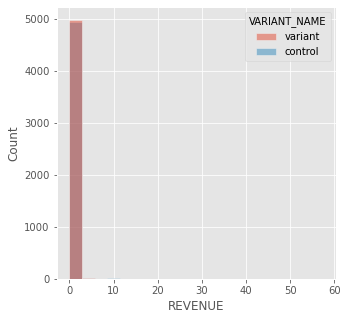

In [ ]:
plt.figure(figsize=(5, 5))
sns.histplot(data=df, x='REVENUE', bins=20, hue='VARIANT_NAME');

**Задача**

Попробуйте сравнить конверсию в тесте и контроле не только визуально, но и с помощью статистических методов таких как z тест пропорций, хи^2.

<AxesSubplot:xlabel='REVENUE', ylabel='Count'>

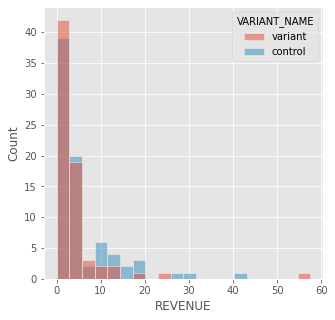

In [ ]:
plt.figure(figsize=(5, 5))
sns.histplot(data=df[df['conversion']==1], x='REVENUE', bins=20, hue='VARIANT_NAME')

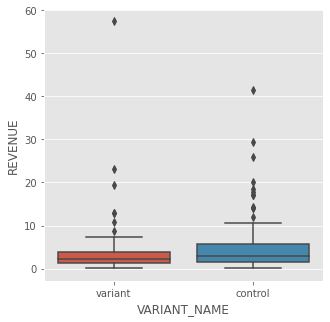

In [ ]:
plt.figure(figsize=(5, 5))
sns.boxplot(data=df[df['conversion']==1], y='REVENUE', x='VARIANT_NAME');

Данных очень мало, распределения ненормальные, много выбросов. По графикам видно, что группа B хуже, чем группа А.
Низкая конверсия в покупку, причем в тестовой группе метрика ниже, чем в контрольной.

**Вторая рекомендация: проверить длительность теста, учесть окно конверсии.**

Для проверки нормальности используем критерий Шапиро-Уилка.

In [ ]:
alpha = 0.05
pvalue = stats.shapiro(df['REVENUE'])[1]
print('Distribution is ' + ['','not'][pvalue < alpha] + ' normal')

Distribution is not normal


**Задача**

Попробуйте другие методы проверки на нормальность, сравните. Например, попробуйте графические (тот же QQ-plot), попробуйте статистические (тот же критерий Колмогорова-Смирнова) и все то, на что хватит воображения.  

Подтвердили предположение о ненормальности данных.
Т.к. распределение ненормальное, в каждой группе мало данных и существуют выбросы, то используем критерий Манна-Уитни.

In [ ]:
stats.mannwhitneyu(x=A['REVENUE'].values, y=B['REVENUE'].values)

MannwhitneyuResult(statistic=12516548.0, pvalue=0.47562494663497656)

p-value больше уровня значимости
0.05, следовательно, статистически значимой разницы между группами нет.

Посчитаем, достаточна ли была мощность наших выборок, чтобы анализировать результаты.

In [ ]:
M1, M2 = A['REVENUE'].mean(), B['REVENUE'].mean()
D1, D2 = A['REVENUE'].var(), B['REVENUE'].var()

In [ ]:
effect_size = (M1-M2)/np.sqrt(((n1-1)*D1 + (n2-1)*D2)/(n1+n2-2))
effect_size

0.028654520674032808

In [ ]:
analysis = TTestIndPower()
analysis.solve_power(effect_size=effect_size, alpha=alpha, power=None, nobs1=n1, ratio=n2/n1)

0.29926052603999687

Мощность теста в районе 29%. С такой мощностью мы не можем быть уверены в результатах теста. Мы могли не получить статистически значимую разницу, т.к. у нас недостаточный объем выборки.
Третья рекомендация: рассчитать требуемый размер выборки и избегать преждевременной остановки теста.

В итоге рекомендуется:

1. Не вводить изменения, на которых происходило тестирование группы B.
2. Уточнить дизайн А/В теста и запустить его заново.

**Задача**

Попробуйте другие статистические тесты на сравнение теста и контроля, сравните с Манна-Утни.

**Задача**

Выберите любой продукт.

Например ваш продукт:

ozon.ru

citilink.ru

telegram

Какие бы ключевые метрики вы выделили?
Опишите почему вы выбрали именно их и можно ли их измерить.



ozon.ru

Ключевые метрики:

Уникальные пользователи, которые посещают сайт раз в месяц / неделю / день (MAU, WAU, DAU).

Конверсия в покупку — процент посетителей сайта, совершивших покупку.

Средний чек — показывает среднюю сумму заказа / покупки клиента (AOV).

Стоимость привлечения клиента (CAC) — сумма, в которую обходится каждый новый клиент.

Цена конверсии в покупку (CPA) — показывает цену целевого действия (покупки).

Коэффициент возврата маркетинговых инвестиций (ROI) — показывает рентабельность затрат на маркетинг.

Средний доход от пользователя (ARPU) — средний доход от каждого активного пользователя за период.

Сколько пользователь принесет денег за время использования продукта (LTV) — предсказание чистого дохода, связанного со всеми будущими отношениями с клиентом.

Процент отказа от корзины — процент посетителей, которые добавляют товары в корзину, но не завершают покупку.

Процент пользователей, оформивших подписку — показатель лояльности.

Индекс потребительской лояльности (NPS) — метрика, определяющая отношение потребителей к компании.

Эти метрики можно измерить с помощью программного обеспечения CRM и различных инструментов (Google Analytics, Яндекс Метрика).



**Задача**

Сформулируйте 5-10 гипотез для выбранного продукта.



Гипотезы:

Введение купонов на скидку позволит увеличить средний чек, потому что увеличится количество товаров в заказе.

Проведение внезапных распродаж позволит увеличить средний доход от пользователя, потому что увеличится количество заказов за месяц.

Уведомление о скидке на отложенный товар позволит увеличить выручку, потому что увеличится количество заказов.

Усовершенствование системы рекомендаций позволит увеличить средний чек, потому что увеличится количество товаров в заказе.

**Задача**

Сделайте приоритезацию гипотез из предыдущего задания с помощью ICE.

| Гипотеза | Impact (влияние) | Confidence (уверенность) | Ease (лёгкость реализации) | ICE Score | Метрика |
| --- | --- | --- | --- | --- | --- |
| Введение купонов на скидку позволит увеличить средний чек, потому что увеличится количество товаров в заказе. | 5 | 6 | 5 | 150 | Средний чек |
| Проведение внезапных распродаж позволит увеличить средний доход от пользователя, потому что увеличится количество заказов за месяц. | 6 | 7 | 6 | 252 | Средний доход от пользователя |
| Уведомление о скидке на отложенный товар позволит увеличить выручку, потому что увеличится количество заказов. | 7 | 8 | 5 | 280 | Конверсия в покупку |
| Усовершенствование системы рекомендаций позволит увеличить средний чек, потому что увеличится количество товаров в заказе. | 8 | 9 | 2 | 144 | Средний чек |

**Задача**

Составьте шаблон дизайна эксперимента для гипотезы, которая набрала больше всего баллов в прошлом задании.

**Шаблон дизайна эксперимента**


1. Гипотеза. \
Уведомление о скидке на отложенный товар позволит увеличить выручку, потому что увеличится количество заказов.


2. Что делаем. \
Разрабатываем прототип системы оповещения о скидке на отложенный товар для приложения. Добавляем возможность подключить/отказаться от уведомлений данного типа.


3. На каких пользователях тестируем. \
Тестируем на пользователях, которые установили приложение и подключили уведомление.


4. Ключевые метрики для оценки эксперимента.
    * Процент конверсий в покупку
    * Средний доход от пользователя
    * Процент отказавшихся от уведомления


5. Ожидаемый эффект. \
Скидка на отложенный товар подтолкнет пользователя к принятию решения о покупке, что увеличит процент конверсий. При этом нужно посмотреть изменения среднего дохода от пользователя, который может увеличиться за счет увеличения числа покупок или уменьшиться за счет уменьшения среднего чека. Кроме того смотрим процент отказавшихся от уведомления, как показатель актуальности системы оповещения.


6. План действий в зависимости от результатов эксперимента. \
Если наш эксперимент будет положительным и мы зафиксируем ожидаемое улучшение в ключевых метриках и не посадим добавочные, то дорабатываем систему оповещения, масштабирем ее на пользователей сайта, добавляем варианты уведомлений.\
Если основные метрики падают или растут недостаточно, либо добавочные метрики падают, откатываем эксперимент.

**Задача**

На основе выбранных продуктов из предыдущего задания, выберите 2 A/B-теста и составьте план эксперимента, чтобы избежать Peeking Problem. Распишите, какие метрики и как вы будете анализировать.

### Интернет-магазин ozon.ru

**Шаблон дизайна эксперимента №1**


1. Гипотеза. \
Уведомление о скидке на отложенный товар позволит увеличить выручку, потому что увеличится количество заказов.


2. Что делаем. \
Разрабатываем прототип системы оповещения о скидке на отложенный товар для приложения. Добавляем возможность подключить/отказаться от уведомлений данного типа.


3. На каких пользователях тестируем. \
Тестируем на пользователях, которые установили приложение и подключили уведомление.


4. Ключевые метрики для оценки эксперимента.
    * Процент конверсий в покупку
    * Средний доход от пользователя
    * Процент отказавшихся от уведомления


5. Ожидаемый эффект. \
Скидка на отложенный товар подтолкнет пользователя к принятию решения о покупке, что увеличит процент конверсий. При этом нужно посмотреть изменения среднего дохода от пользователя, который может увеличиться за счет увеличения числа покупок или уменьшиться за счет уменьшения среднего чека. Кроме того смотрим процент отказавшихся от уведомления, как показатель актуальности системы оповещения.


6. План действий в зависимости от результатов эксперимента. \
Если наш эксперимент будет положительным и мы зафиксируем ожидаемое улучшение в ключевых метриках и не посадим добавочные, то дорабатываем систему оповещения, масштабирем ее на пользователей сайта, добавляем варианты уведомлений.\
Если основные метрики падают или растут недостаточно, либо добавочные метрики падают, откатываем эксперимент.


**Шаблон дизайна эксперимента №2**


1. Гипотеза. \
Усовершенствование системы рекомендаций позволит увеличить средний чек, потому что увеличится количество товаров в заказе.


2. Что делаем. \
Вносим изменения в рекомендательную систему.


3. На каких пользователях тестируем. \
Случайным образом выбираем из потока пользователей 50% распределения и направляем на модифицированный сервис. Остальные 50% посетителей оставляем на прежней версии сервиса.


4. Ключевые метрики для оценки эксперимента.
    * средний чек
    * среднее количество товаров в заказе


5. Ожидаемый эффект. \
Увеличение количества товаров в заказе и среднего чека в тестовой группе по сравнению с контрольной группой.


6. План действий в зависимости от результатов эксперимента. \
Если наш эксперимент будет положительным и мы зафиксируем ожидаемое улучшение в ключевых метриках и не посадим добавочные, то внедряем изменения для всех пользователей.\
Если основные метрики падают или растут недостаточно, либо добавочные метрики падают, откатываем эксперимент.



**План экспериментов тестирования гипотез 1 и 2**


1. Формирование и приоритезация гипотез
- [ ] Составление и приоритезация бэклога эксперимента


2. Проектирование дизайна эксперимента для проверки гипотезы
- [ ] Сформулирована цель и гипотеза
- [ ] Выбраны метрики и длительностьность эксперимента
- [ ] Проверена инфраструктура
- [ ] Все ответственные за эксперимент оповещены, не позднее, чем за день до начала эксперимента


3. Запуск теста
- [ ] Выполнено корректное сплитование юзеров
- [ ] Все стейкхолдеры знают о запуске теста и его деталях
- [ ] Создан дашбоард. Доступ к которому запрещен для руководителей и разрешен только для тех, кто отвечает за проведение эксперимента


4. Сбор и анализ данных
- [ ] Настраиваем процессы так, чтобы ежедневно видеть актуальные данные для мониторинга KPI. В заранее подготовленных дашбордах следим за ходом эксперимента с самого запуска: проверяем, равномерно ли набираются группы, нет ли критичных проблем после запуска теста, которые могут повлиять на результаты.
- [ ] По завершению, посчитаны результаты и сделано описание
- [ ] По готовности, результат направлен всем заинтересованным


5. Принятие решения на основе результатов теста
- [ ] При положительном резльтате теста, изменение принимается

**Задача**

Проделайте все те же задания, но уже для любого другого продукта, которым вы пользуетесь или просто, который вам известен. Желательно, чтобы этот продукт был известен и вашему возможному интервьюеру.